In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("Advertising.csv")

df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [3]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)

df.info()

Shape: (200, 4)

Columns:
Index(['TV', 'radio', 'newspaper', 'sales'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [4]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [5]:
df.isnull().sum()

TV           0
radio        0
newspaper    0
sales        0
dtype: int64

In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
df = df.drop_duplicates()

In [14]:
df.columns

Index(['TV', 'radio', 'newspaper', 'sales'], dtype='object')

In [8]:
df.describe()

,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


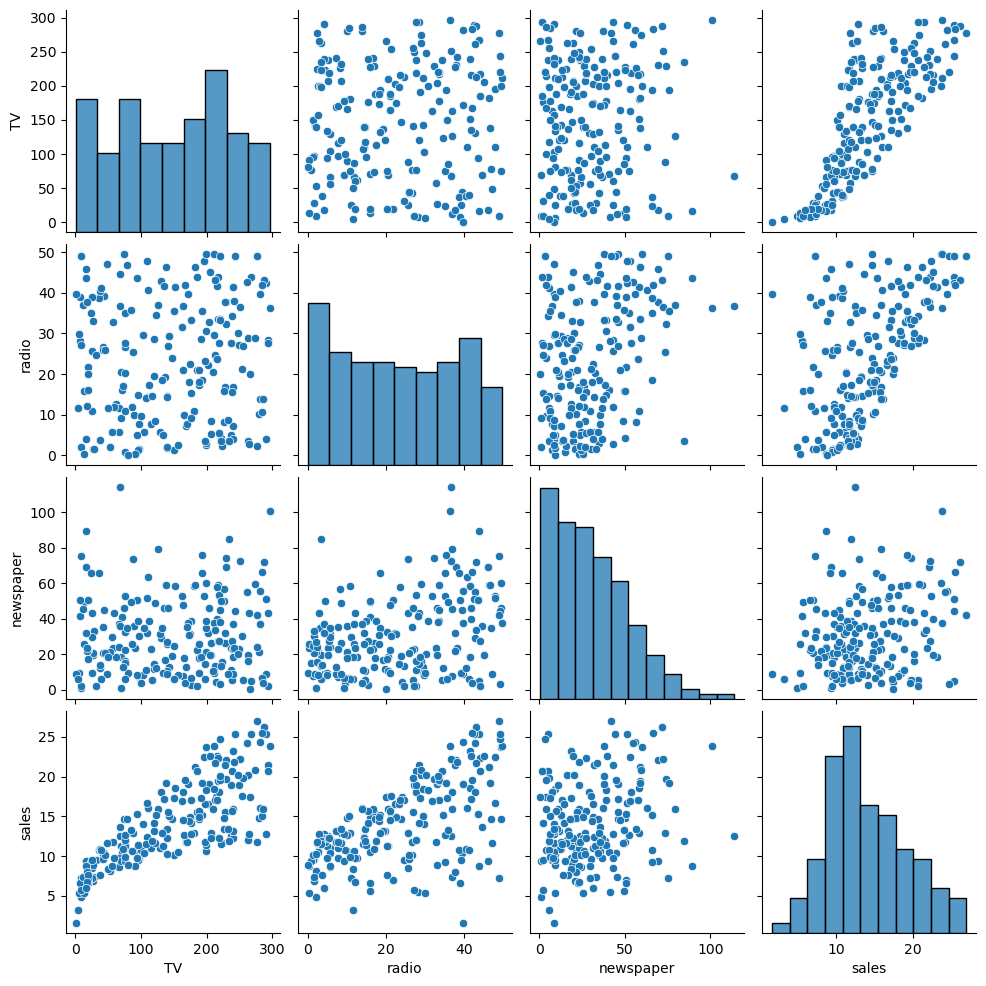

In [12]:
sns.pairplot(df)
plt.show()

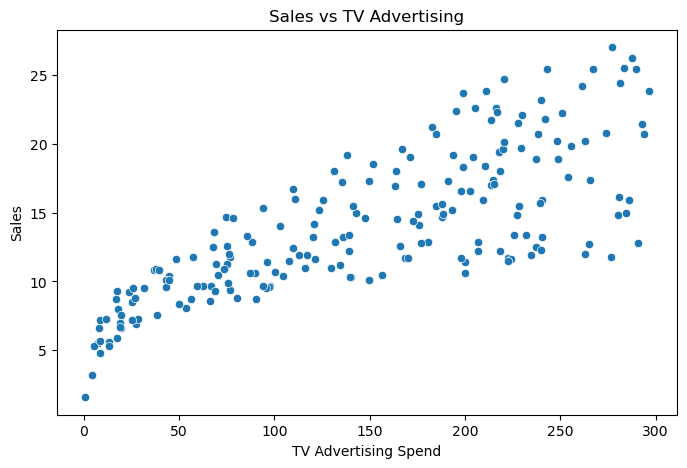

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="TV", y="sales")

plt.title("Sales vs TV Advertising")
plt.xlabel("TV Advertising Spend")
plt.ylabel("Sales")
plt.show()

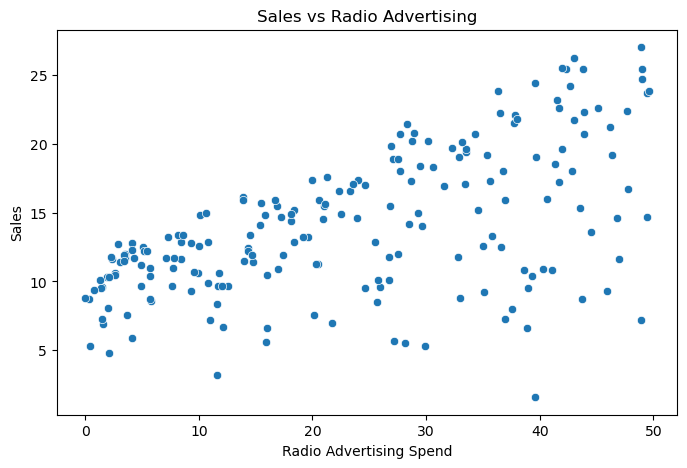

In [18]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="radio", y="sales")

plt.title("Sales vs Radio Advertising")
plt.xlabel("Radio Advertising Spend")
plt.ylabel("Sales")
plt.show()

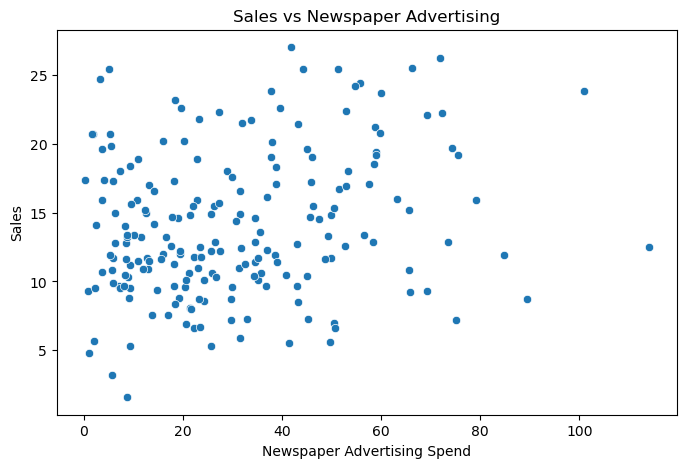

In [20]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="newspaper", y="sales")

plt.title("Sales vs Newspaper Advertising")
plt.xlabel("Newspaper Advertising Spend")
plt.ylabel("Sales")
plt.show()

In [21]:
correlation = df.corr()

correlation

,TV,radio,newspaper,sales
TV,1.000000,0.054809,0.056648,0.782224
radio,0.054809,1.000000,0.354104,0.576223
newspaper,0.056648,0.354104,1.000000,0.228299
sales,0.782224,0.576223,0.228299,1.000000


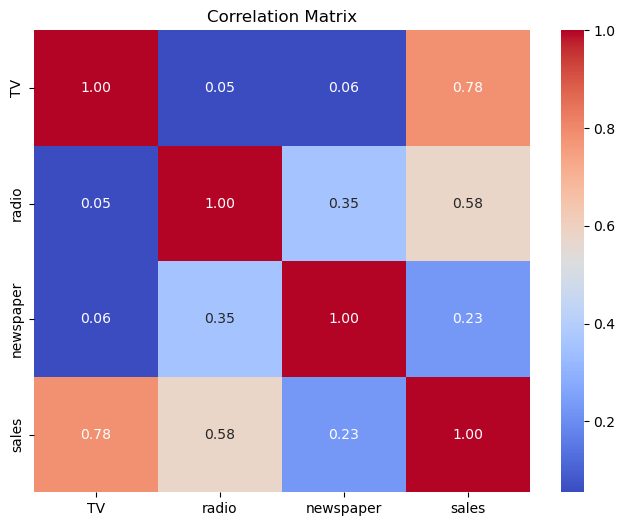

In [22]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [24]:
X = df[["TV", "radio", "newspaper"]]

In [26]:
y = df["sales"]

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [28]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (160, 3)
Testing data: (40, 3)


In [29]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [30]:
y_pred_linear = linear_model.predict(X_test)

In [31]:
mae_linear = mean_absolute_error(y_test, y_pred_linear)

In [32]:
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))

In [33]:
r2_linear = r2_score(y_test, y_pred_linear)

In [34]:
print("Linear Regression Results")
print("-------------------------")
print("MAE :", mae_linear)
print("RMSE:", rmse_linear)
print("R²  :", r2_linear)

Linear Regression Results
-------------------------
MAE : 1.4607567168117606
RMSE: 1.7815996615334502
R²  : 0.899438024100912


In [35]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": linear_model.coef_
})

coefficients

,Feature,Coefficient
0,TV,0.044730
1,radio,0.189195
2,newspaper,0.002761


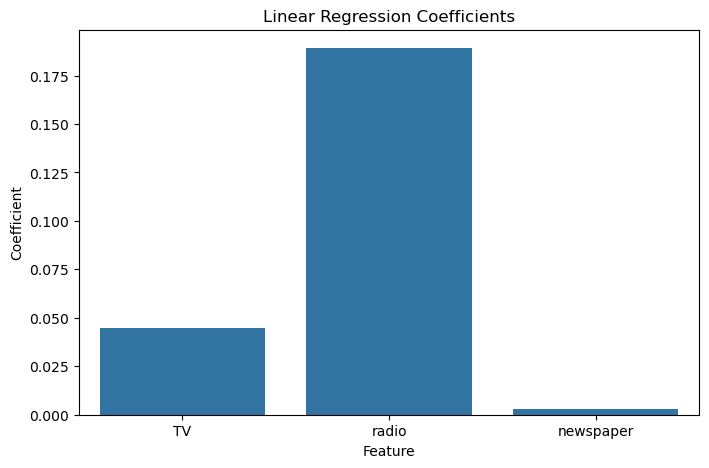

In [36]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=coefficients,
    x="Feature",
    y="Coefficient"
)

plt.title("Linear Regression Coefficients")
plt.show()

In [37]:
print("Intercept:", linear_model.intercept_)

Intercept: 2.9790673381226274


In [38]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [39]:
y_pred_rf = rf_model.predict(X_test)

In [40]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest Results
---------------------
MAE : 0.6287125000000021
RMSE: 0.7572349907723515
R²  : 0.9818333477552758


In [41]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mae_linear,
        mae_rf
    ],
    "RMSE": [
        rmse_linear,
        rmse_rf
    ],
    "R2 Score": [
        r2_linear,
        r2_rf
    ]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.460757,1.781600,0.899438
1,Random Forest,0.628713,0.757235,0.981833


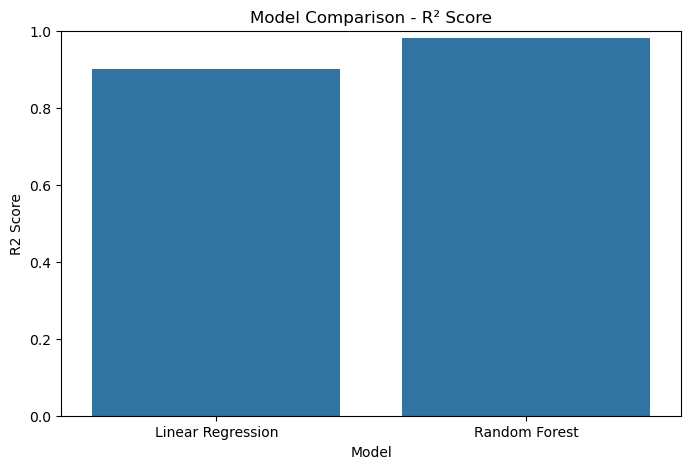

In [42]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x="Model",
    y="R2 Score"
)

plt.title("Model Comparison - R² Score")
plt.ylim(0, 1)
plt.show()

In [43]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,TV,0.624727
1,radio,0.362119
2,newspaper,0.013153


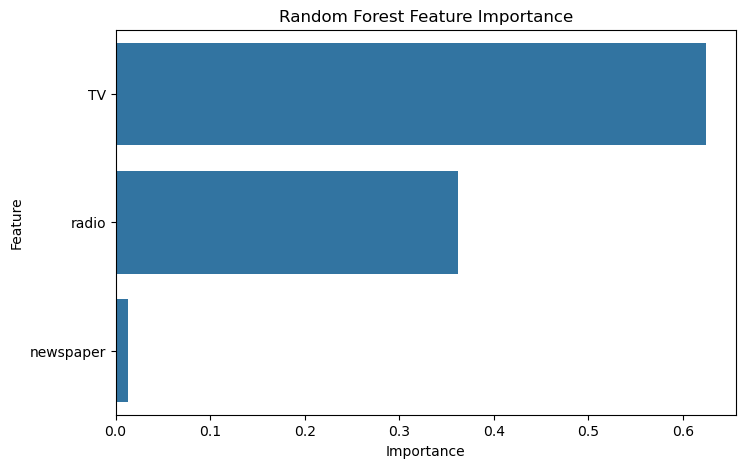

In [44]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.show()

In [45]:
best_predictions = y_pred_rf
best_model_name = "Random Forest"

In [46]:
best_predictions = y_pred_linear
best_model_name = "Linear Regression"

In [47]:
residuals = y_test - best_predictions

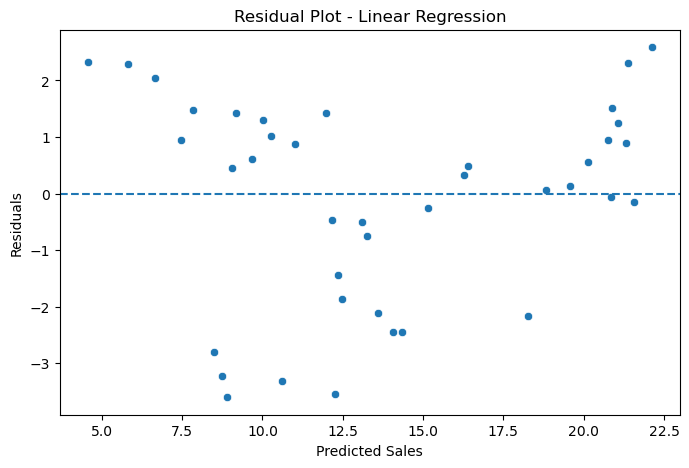

In [48]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=best_predictions,
    y=residuals
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title(f"Residual Plot - {best_model_name}")

plt.show()

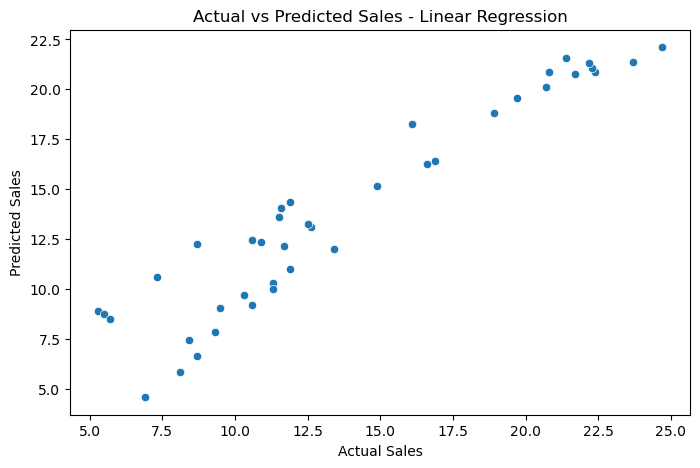

In [49]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_test,
    y=best_predictions
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title(f"Actual vs Predicted Sales - {best_model_name}")

plt.show()

In [52]:
def predict_sales(tv, radio, newspaper):
    data = pd.DataFrame({
        "TV": [tv],
        "radio": [radio],
        "newspaper": [newspaper]
    })
    
    prediction = rf_model.predict(data)
    
    return prediction[0]

In [53]:
predicted_sales = predict_sales(
    tv=150,
    radio=30,
    newspaper=20
)

print("Predicted Sales:", predicted_sales)

Predicted Sales: 16.72300000000001


## Conclusion

In this project, we developed a machine learning model to predict product
sales using advertising expenditure across TV, Radio, and Newspaper.

We first performed exploratory data analysis using descriptive statistics,
pairplots, scatter plots, and a correlation heatmap.

Linear Regression was trained as the baseline model, followed by a Random
Forest Regressor. Both models were evaluated using Mean Absolute Error (MAE),
Root Mean Squared Error (RMSE), and R² score.

Based on the model results, the model with the lower MAE and RMSE and higher
R² score was considered the better-performing model.

Feature analysis showed that TV advertising has the strongest influence on
sales among the three advertising channels. Radio also contributes
significantly, while Newspaper generally has a comparatively smaller impact.

The residual plot was used to check whether the prediction errors were
randomly distributed without strong systematic patterns.

Overall, the project demonstrates how regression techniques can be used to
understand the relationship between advertising expenditure and product sales
and make predictions for future advertising scenarios.